In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from sqlalchemy import create_engine
from dotenv import load_dotenv
import os
from pathlib import Path

# Load .env from the root folder
BASE_DIR = Path.cwd().parent
load_dotenv(dotenv_path=BASE_DIR / ".env")

# Connect to Neon
DATABASE_URL = os.getenv("DATABASE_URL")
engine = create_engine(DATABASE_URL)

# Test connection
with engine.connect() as conn:
    print("✅ Connected to Neon PostgreSQL successfully!")

✅ Connected to Neon PostgreSQL successfully!


In [2]:
def run_query(sql_query):
    """Execute a SQL query and return a Pandas DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(sql_query, conn)

print("✅ Helper function ready.")

✅ Helper function ready.


In [3]:
query_kpis = """
SELECT 
    ROUND(SUM("TotalAmount")::numeric, 2) AS total_revenue,
    COUNT(DISTINCT "Invoice") AS total_orders,
    COUNT(DISTINCT "CustomerID") AS total_customers,
    SUM("Quantity") AS total_units_sold,
    ROUND((SUM("TotalAmount") / COUNT(DISTINCT "Invoice"))::numeric, 2) AS avg_order_value
FROM retail_transactions;
"""

df_kpis = run_query(query_kpis)
print(df_kpis.to_string(index=False))

 total_revenue  total_orders  total_customers  total_units_sold  avg_order_value
   17374804.27         36969             5878        10513952.0           469.98


In [4]:
query_monthly = """
SELECT 
    DATE_TRUNC('month', "InvoiceDate")::date AS month,
    ROUND(SUM("TotalAmount")::numeric, 2) AS monthly_revenue,
    COUNT(DISTINCT "Invoice") AS orders
FROM retail_transactions
GROUP BY DATE_TRUNC('month', "InvoiceDate")
ORDER BY month;
"""

df_monthly = run_query(query_monthly)
df_monthly['month'] = pd.to_datetime(df_monthly['month'])

fig = px.line(
    df_monthly, 
    x='month', 
    y='monthly_revenue', 
    title='📈 Monthly Revenue Trend',
    markers=True
)
fig.update_layout(xaxis_title='Month', yaxis_title='Revenue (£)')
fig.show()

In [5]:
query_top_products = """
SELECT 
    "Description",
    SUM("Quantity") AS units_sold,
    ROUND(SUM("TotalAmount")::numeric, 2) AS revenue
FROM retail_transactions
GROUP BY "Description"
ORDER BY revenue DESC
LIMIT 10;
"""

df_top = run_query(query_top_products)

fig = px.bar(
    df_top, 
    x='revenue', 
    y='Description', 
    orientation='h',
    title='🏆 Top 10 Products by Revenue',
    text='revenue',
    color='revenue',
    color_continuous_scale='Viridis'
)
fig.update_layout(yaxis={'categoryorder':'total ascending'}, height=500)
fig.show()

In [6]:
query_country = """
SELECT 
    "Country",
    ROUND(SUM("TotalAmount")::numeric, 2) AS revenue
FROM retail_transactions
GROUP BY "Country"
ORDER BY revenue DESC
LIMIT 10;
"""

df_country = run_query(query_country)

fig = px.pie(
    df_country, 
    values='revenue', 
    names='Country',
    title='🌍 Revenue by Country (Top 10)',
    hole=0.4
)
fig.show()

In [7]:
query_cohort = """
WITH first_purchase AS (
    SELECT 
        "CustomerID",
        DATE_TRUNC('month', MIN("InvoiceDate"))::date AS cohort_month
    FROM retail_transactions
    GROUP BY "CustomerID"
)
SELECT 
    fp.cohort_month,
    COUNT(DISTINCT fp."CustomerID") AS cohort_size,
    COUNT(DISTINCT CASE 
        WHEN DATE_TRUNC('month', t."InvoiceDate") = fp.cohort_month + INTERVAL '1 month' 
        THEN t."CustomerID" END) AS month_1,
    COUNT(DISTINCT CASE 
        WHEN DATE_TRUNC('month', t."InvoiceDate") = fp.cohort_month + INTERVAL '3 month' 
        THEN t."CustomerID" END) AS month_3
FROM first_purchase fp
LEFT JOIN retail_transactions t ON fp."CustomerID" = t."CustomerID"
GROUP BY fp.cohort_month
ORDER BY fp.cohort_month;
"""

df_cohort = run_query(query_cohort)
df_cohort['retention_1m_pct'] = (df_cohort['month_1'] / df_cohort['cohort_size'] * 100).round(2)
df_cohort['retention_3m_pct'] = (df_cohort['month_3'] / df_cohort['cohort_size'] * 100).round(2)
print(df_cohort[['cohort_month', 'cohort_size', 'retention_1m_pct', 'retention_3m_pct']].to_string(index=False))

cohort_month  cohort_size  retention_1m_pct  retention_3m_pct
  2009-12-01          955             35.29             42.51
  2010-01-01          383             20.63             30.55
  2010-02-01          374             23.80             29.14
  2010-03-01          443             18.96             24.15
  2010-04-01          294             19.39             16.33
  2010-05-01          254             15.75             17.32
  2010-06-01          270             17.41             20.37
  2010-07-01          186             15.59             29.57
  2010-08-01          162             20.37             32.10
  2010-09-01          243             22.63             12.35
  2010-10-01          377             25.73             12.47
  2010-11-01          325             17.54              9.54
  2010-12-01           76              9.21              9.21
  2011-01-01           71             16.90             19.72
  2011-02-01          124             16.13             18.55
  2011-0

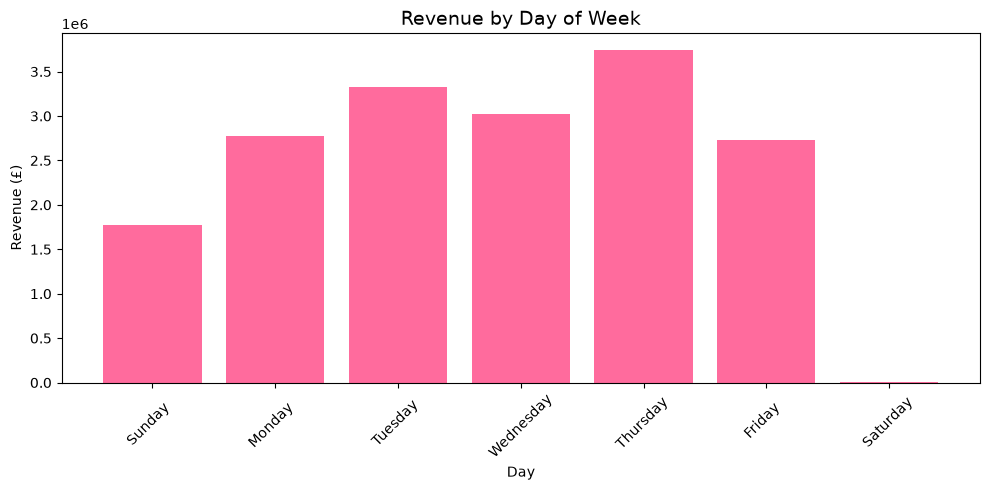

In [8]:
import matplotlib.pyplot as plt

query_dow = """
SELECT 
    TO_CHAR("InvoiceDate", 'Day') AS day_of_week,
    EXTRACT(DOW FROM "InvoiceDate") AS dow_num,
    ROUND(SUM("TotalAmount")::numeric, 2) AS revenue
FROM retail_transactions
GROUP BY day_of_week, dow_num
ORDER BY dow_num;
"""

df_dow = run_query(query_dow)

plt.figure(figsize=(10, 5))
plt.bar(df_dow['day_of_week'], df_dow['revenue'], color='#FF6B9D')
plt.title('Revenue by Day of Week', fontsize=14)
plt.xlabel('Day')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()